# What Drives House Prices in California?
### Linear regression, diagnostics and influential-point analysis on the 1990 California Housing census data

**Author:** Bashir Omondi Nuru

---

**Business question.** How well does neighbourhood income explain median house value, and how much do we gain by
adding location, housing age and household structure? Along the way: is the linear model trustworthy, and which
districts have outsized influence on the fit?

**What this notebook demonstrates**

| Skill | Where |
|---|---|
| Data loading and feature engineering from raw census files | §1–2 |
| Data-quality audit (missing values, duplicates, censored values) | §2 |
| Exploratory analysis: distributions, correlations, geography | §3 |
| Simple OLS with `statsmodels`, interpretation of coefficients | §4 |
| Regression diagnostics: residuals, Q–Q, Breusch–Pagan, Cook's distance | §5–6 |
| Sensitivity analysis: refitting without influential and censored points | §6–7 |
| Multiple regression, multicollinearity (VIF), robust standard errors | §8 |
| Out-of-sample validation (train/test split, RMSE, MAE) | §9 |
| Communicating results to a non-technical audience | §10 |

**Data.** 20,640 census block groups (districts) from the 1990 U.S. Census, originally published by Pace & Barry (1997)
and distributed with scikit-learn as `fetch_california_housing`. The raw files are in `data/`.

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.model_selection import train_test_split
from pathlib import Path

# Consistent, colour-blind-safe styling for every chart
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e0", "axes.edgecolor": "#b5b4ae",
    "axes.titleweight": "bold", "figure.dpi": 110,
})
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
pd.set_option("display.float_format", "{:,.3f}".format)

The raw file has one row per district with **totals** (total rooms, total bedrooms, population, households).
To match the scikit-learn version of the dataset, I convert totals into **per-household averages**, and express
house value in units of $100,000.

In [2]:
DATA_DIR = Path("../data")
raw_cols = ["longitude", "latitude", "housingMedianAge", "totalRooms", "totalBedrooms",
            "population", "households", "medianIncome", "medianHouseValue"]
raw = pd.read_csv(DATA_DIR / "cal_housing.data", header=None, names=raw_cols)

df = pd.DataFrame({
    "MedInc":     raw["medianIncome"],                       # tens of thousands of USD
    "HouseAge":   raw["housingMedianAge"],
    "AveRooms":   raw["totalRooms"] / raw["households"],
    "AveBedrms":  raw["totalBedrooms"] / raw["households"],
    "Population": raw["population"],
    "AveOccup":   raw["population"] / raw["households"],
    "Latitude":   raw["latitude"],
    "Longitude":  raw["longitude"],
    "MedianHouseValue": raw["medianHouseValue"] / 100_000,   # hundreds of thousands of USD
})
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,"2,401.000",2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 2. Data-quality audit

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(), "median": df.median(), "max": df.max(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
quality

Duplicate rows: 0


,dtype,missing,unique,min,median,max
MedInc,float64,0,12928,0.500,3.535,15.000
HouseAge,float64,0,52,1.000,29.000,52.000
AveRooms,float64,0,19392,0.846,5.229,141.909
AveBedrms,float64,0,14233,0.333,1.049,34.067
Population,float64,0,3888,3.000,"1,166.000","35,682.000"
AveOccup,float64,0,18841,0.692,2.818,"1,243.333"
Latitude,float64,0,862,32.540,34.260,41.950
Longitude,float64,0,844,-124.350,-118.490,-114.310
MedianHouseValue,float64,0,3842,0.150,1.797,5.000


Three columns look **censored** (top-coded) by the Census Bureau: house value stops at \$500,001, housing age stops at 52 years and median income stops at 15 (\$150,000).
A large spike at the maximum is a sign that the true values are higher than recorded. This matters because a linear
model will be pulled down at the top end.

In [4]:
cap_value = df["MedianHouseValue"].max()
cap_age = df["HouseAge"].max()
n_cap_value = (df["MedianHouseValue"] >= cap_value).sum()
n_cap_age = (df["HouseAge"] >= cap_age).sum()
print(f"House value capped at ${cap_value*100_000:,.0f}: {n_cap_value:,} districts ({n_cap_value/len(df):.1%})")
print(f"House age capped at {cap_age:.0f} years:       {n_cap_age:,} districts ({n_cap_age/len(df):.1%})")
n_cap_inc = (df["MedInc"] >= df["MedInc"].max()).sum()
print(f"Median income capped at $150,000:   {n_cap_inc:,} districts ({n_cap_inc/len(df):.1%})")

# Extreme per-household averages usually signal group quarters (dorms, prisons, resorts)
for col in ["AveRooms", "AveOccup"]:
    q99 = df[col].quantile(0.99)
    print(f"{col}: 99th percentile = {q99:.1f}, max = {df[col].max():.1f}")

House value capped at $500,001: 965 districts (4.7%)
House age capped at 52 years:       1,273 districts (6.2%)
Median income capped at $150,000:   49 districts (0.2%)
AveRooms: 99th percentile = 10.4, max = 141.9
AveOccup: 99th percentile = 5.4, max = 1243.3


## 3. Exploratory data analysis

### 3.1 Distributions

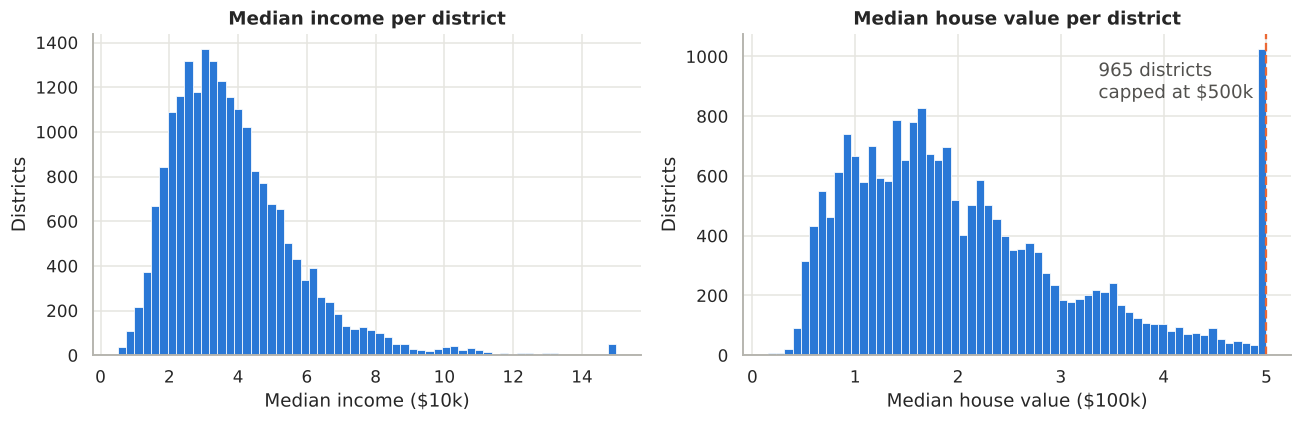

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["MedInc"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Median income per district", xlabel="Median income ($10k)", ylabel="Districts")
axes[1].hist(df["MedianHouseValue"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].axvline(cap_value, color=ORANGE, linestyle="--", linewidth=1.5)
axes[1].annotate(f"{n_cap_value:,} districts\ncapped at $500k", xy=(cap_value, axes[1].get_ylim()[1]*0.8),
                 xytext=(-110, 0), textcoords="offset points", color="#52514e")
axes[1].set(title="Median house value per district", xlabel="Median house value ($100k)", ylabel="Districts")
plt.tight_layout(); plt.savefig(FIG_DIR / "distributions.png", bbox_inches="tight"); plt.show()

Both variables are **right-skewed**, and house value has a clear spike at the cap.

### 3.2 Correlations

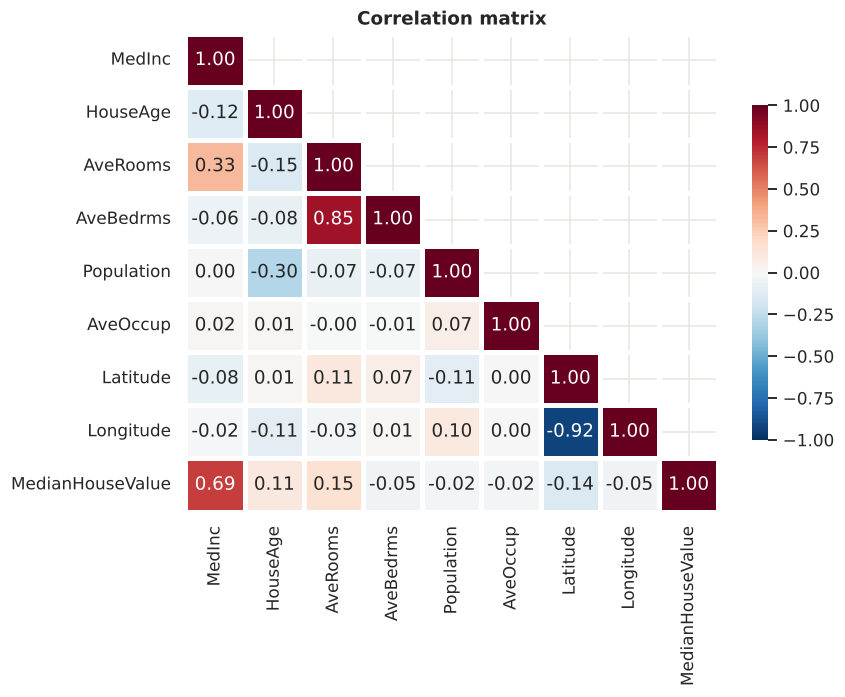

,corr with value
MedInc,0.688
AveRooms,0.152
Latitude,-0.144
HouseAge,0.106
AveBedrms,-0.047
Longitude,-0.046
Population,-0.025
AveOccup,-0.024


In [6]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout(); plt.savefig(FIG_DIR / "correlation_matrix.png", bbox_inches="tight"); plt.show()

corr["MedianHouseValue"].drop("MedianHouseValue").sort_values(key=abs, ascending=False).to_frame("corr with value")

Income is by far the strongest single predictor. `AveRooms` and `AveBedrms` are strongly correlated with each other,
which is a warning sign for multicollinearity when both go into one model (checked with VIF in §8).

### 3.3 Income vs. house value

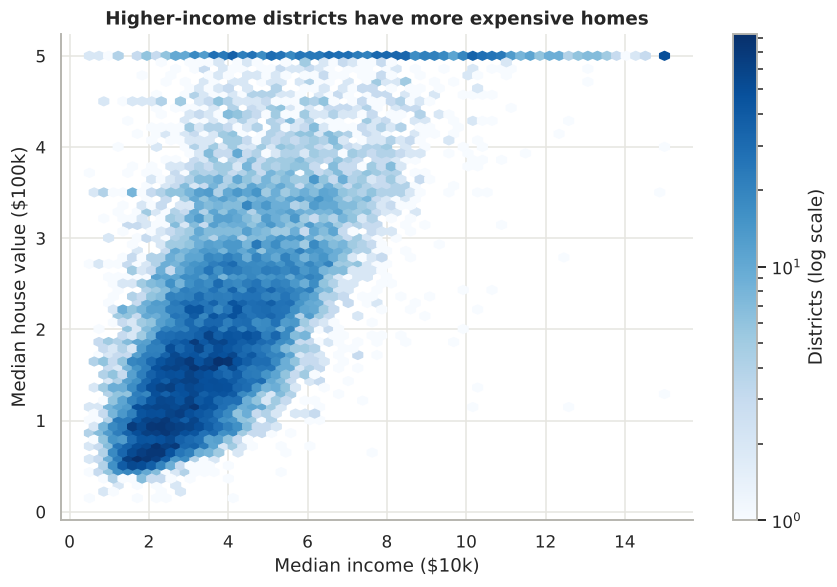

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(df["MedInc"], df["MedianHouseValue"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Districts (log scale)")
ax.set(title="Higher-income districts have more expensive homes",
       xlabel="Median income ($10k)", ylabel="Median house value ($100k)")
plt.tight_layout(); plt.savefig(FIG_DIR / "income_vs_value.png", bbox_inches="tight"); plt.show()

The relationship is positive and roughly linear, but the spread widens as income rises, and the cap at 5.0 makes a horizontal ceiling.

### 3.4 Geography

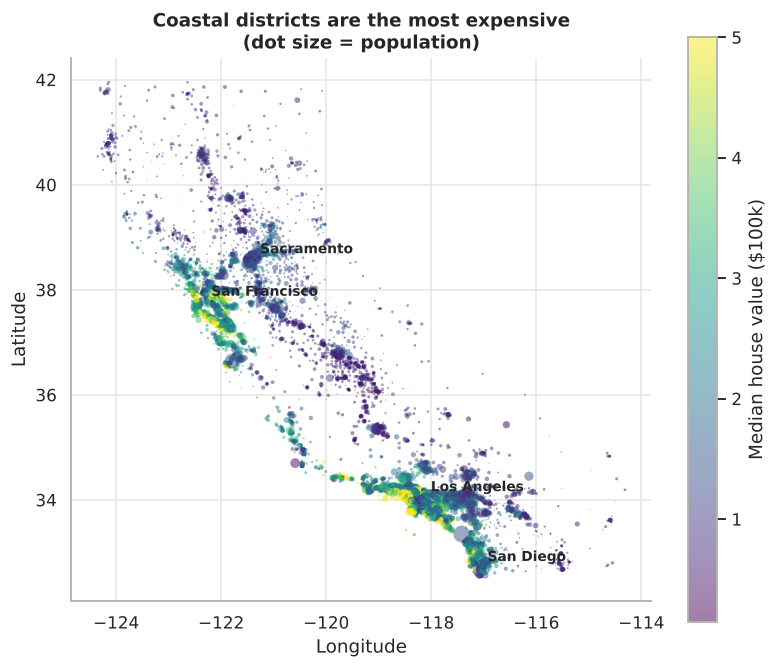

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 7))
sc = ax.scatter(df["Longitude"], df["Latitude"], c=df["MedianHouseValue"], cmap="viridis",
                s=df["Population"] / 300, alpha=0.5, linewidths=0)
fig.colorbar(sc, ax=ax, label="Median house value ($100k)", shrink=0.8)
for name, lon, lat in [("San Francisco", -122.42, 37.77), ("Los Angeles", -118.24, 34.05),
                       ("San Diego", -117.16, 32.72), ("Sacramento", -121.49, 38.58)]:
    ax.annotate(name, (lon, lat), xytext=(8, 4), textcoords="offset points", fontsize=9, weight="bold")
ax.set(title="Coastal districts are the most expensive\n(dot size = population)",
       xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(FIG_DIR / "geography.png", bbox_inches="tight"); plt.show()

Location clearly matters: the Bay Area and the Los Angeles / San Diego coastline are expensive whatever the income. Income alone will miss this.

## 4. Baseline model: simple linear regression

$$\text{MedianHouseValue}_i = \beta_0 + \beta_1 \cdot \text{MedInc}_i + \varepsilon_i$$

In [9]:
X = df["MedInc"]
y = df["MedianHouseValue"]
X_const = sm.add_constant(X)
model = sm.OLS(y, X_const).fit()
residuals = model.resid
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       MedianHouseValue   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                 1.856e+04
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:55:45   Log-Likelihood:                -25623.
No. Observations:               20640   AIC:                         5.125e+04
Df Residuals:                   20638   BIC:                         5.127e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4509      0.013     34.082      0.0

In [10]:
b0, b1 = model.params
lo, hi = model.conf_int().loc["MedInc"]
print(f"R-squared: {model.rsquared:.3f}")
print(f"Each extra $10,000 of median income is associated with ${b1*100_000:,.0f} higher median house value "
      f"(95% CI ${lo*100_000:,.0f} to ${hi*100_000:,.0f}).")

positive_residuals = (residuals > 0).sum()
negative_residuals = (residuals < 0).sum()
print(f"Under-predicted (positive residuals): {positive_residuals:,}")
print(f"Over-predicted  (negative residuals): {negative_residuals:,}")

R-squared: 0.473
Each extra $10,000 of median income is associated with $41,794 higher median house value (95% CI $41,192 to $42,395).
Under-predicted (positive residuals): 8,375
Over-predicted  (negative residuals): 12,265


More residuals are negative than positive, yet the residuals still sum to zero. So the model **slightly over-predicts
most districts and badly under-predicts a smaller number** (mostly the expensive, capped ones). The residual
distribution is skewed, which the diagnostics below confirm.

## 5. Regression diagnostics

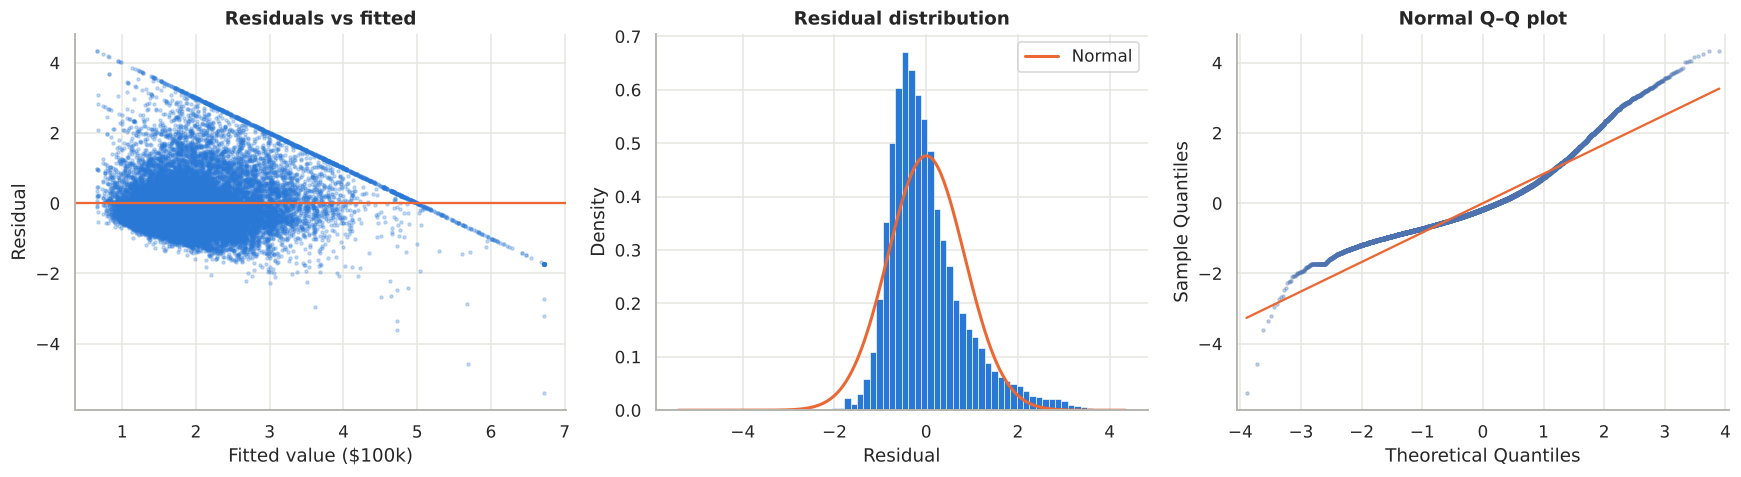

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(model.fittedvalues, residuals, s=4, alpha=0.25, color=BLUE)
axes[0].axhline(0, color=ORANGE, linewidth=1.5)
axes[0].set(title="Residuals vs fitted", xlabel="Fitted value ($100k)", ylabel="Residual")

axes[1].hist(residuals, bins=70, color=BLUE, edgecolor="white", linewidth=0.4, density=True)
xs = np.linspace(residuals.min(), residuals.max(), 300)
axes[1].plot(xs, stats.norm.pdf(xs, 0, residuals.std()), color=ORANGE, linewidth=2, label="Normal")
axes[1].set(title="Residual distribution", xlabel="Residual", ylabel="Density"); axes[1].legend()

sm.qqplot(residuals, line="s", ax=axes[2], markersize=2, alpha=0.3, color=BLUE)
axes[2].get_lines()[1].set_color(ORANGE)
axes[2].set_title("Normal Q–Q plot")

plt.tight_layout(); plt.savefig(FIG_DIR / "diagnostics_simple.png", bbox_inches="tight"); plt.show()

- **Residuals vs fitted:** the diagonal band in the upper right is the \$500k cap (actual value fixed while the prediction keeps rising). The funnel shape suggests **heteroscedasticity**.
- **Q–Q plot:** heavy tails, so the residuals are not normal.

The Breusch–Pagan test checks heteroscedasticity formally:

In [12]:
bp_lm, bp_p, _, _ = het_breuschpagan(residuals, X_const)
print(f"Breusch–Pagan LM = {bp_lm:,.1f}, p-value = {bp_p:.2e}")
print("Constant variance rejected -> use heteroscedasticity-robust (HC3) standard errors for inference."
      if bp_p < 0.05 else "No evidence against constant variance.")

Breusch–Pagan LM = 138.9, p-value = 4.72e-32
Constant variance rejected -> use heteroscedasticity-robust (HC3) standard errors for inference.


## 6. Influential points: Cook's distance

Cook's distance measures how much the whole fitted line would move if one district were removed.
I use the common rule of thumb **D > 4/n**.

In [13]:
influence = model.get_influence()
cooks_d = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag
stud_resid = influence.resid_studentized_external

n = len(X)
threshold = 4 / n
influential_points = np.where(cooks_d > threshold)[0]
print(f"Threshold 4/n = {threshold:.6f}")
print(f"Influential districts: {influential_points.shape[0]:,} ({influential_points.shape[0]/n:.1%})")

Threshold 4/n = 0.000194
Influential districts: 1,230 (6.0%)


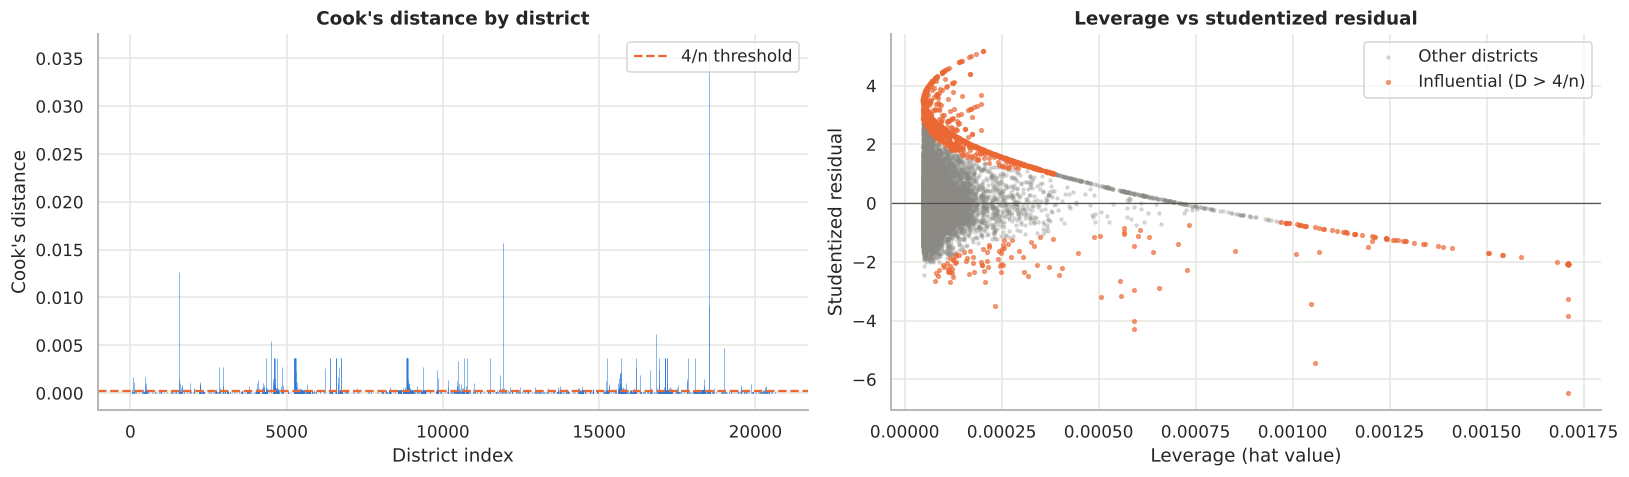

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].vlines(np.arange(n), 0, cooks_d, color=BLUE, linewidth=0.5, alpha=0.7)
axes[0].axhline(threshold, color=ORANGE, linestyle="--", linewidth=1.5, label="4/n threshold")
axes[0].set(title="Cook's distance by district", xlabel="District index", ylabel="Cook's distance")
axes[0].legend()

is_inf = cooks_d > threshold
axes[1].scatter(leverage[~is_inf], stud_resid[~is_inf], s=4, alpha=0.25, color=GREY, label="Other districts")
axes[1].scatter(leverage[is_inf], stud_resid[is_inf], s=6, alpha=0.6, color=ORANGE, label="Influential (D > 4/n)")
axes[1].axhline(0, color="#52514e", linewidth=0.8)
axes[1].set(title="Leverage vs studentized residual", xlabel="Leverage (hat value)", ylabel="Studentized residual")
axes[1].legend()

plt.tight_layout(); plt.savefig(FIG_DIR / "cooks_distance.png", bbox_inches="tight"); plt.show()

**Who are the influential districts?** Comparing their profile with the rest of the data:

In [15]:
profile = pd.DataFrame({
    "Influential": df.iloc[influential_points].mean(numeric_only=True),
    "All others":  df.drop(df.index[influential_points]).mean(numeric_only=True),
})
share_capped = (df.iloc[influential_points]["MedianHouseValue"] >= cap_value).mean()
print(f"Share of influential districts at the $500k cap: {share_capped:.1%} "
      f"(vs {n_cap_value/n:.1%} overall)")
profile.loc[["MedInc", "MedianHouseValue", "HouseAge", "AveRooms", "Latitude", "Longitude"]]

Share of influential districts at the $500k cap: 58.9% (vs 4.7% overall)


,Influential,All others
MedInc,6.003,3.736
MedianHouseValue,4.518,1.913
HouseAge,33.894,28.306
AveRooms,5.972,5.395
Latitude,35.239,35.657
Longitude,-119.625,-119.566


### 6.1 Sensitivity check: does dropping influential points change the story?

In [16]:
keep = ~is_inf
model_no_inf = sm.OLS(y[keep], X_const[keep]).fit()
pd.DataFrame({
    "All data": [model.params["MedInc"], model.params["const"], model.rsquared, int(model.nobs)],
    "Without influential points": [model_no_inf.params["MedInc"], model_no_inf.params["const"],
                                   model_no_inf.rsquared, int(model_no_inf.nobs)],
}, index=["Slope (MedInc)", "Intercept", "R-squared", "n"])

,All data,Without influential points
Slope (MedInc),0.418,0.431
Intercept,0.451,0.303
R-squared,0.473,0.549
n,"20,640.000","19,410.000"


Dropping influential points raises R² because the hardest cases are gone, **not** because the model got better.
Those districts are real (mostly expensive coastal areas), so I keep them and treat this only as a robustness check.
The direction and rough size of the income effect hold either way.

## 7. Handling the censored target

In [17]:
uncapped = df["MedianHouseValue"] < cap_value
model_uncapped = sm.OLS(y[uncapped], X_const[uncapped]).fit()
print(f"Slope with capped rows:    {model.params['MedInc']:.4f}  (R² {model.rsquared:.3f})")
print(f"Slope without capped rows: {model_uncapped.params['MedInc']:.4f}  (R² {model_uncapped.rsquared:.3f})")

Slope with capped rows:    0.4179  (R² 0.473)
Slope without capped rows: 0.3999  (R² 0.413)


Removing capped rows changes the slope, so the cap biases the estimate. For the rest of the analysis I **exclude
capped districts** for modelling. The trade-off is that the model is not meant for districts above \$500k.
(A Tobit or censored-regression model would be the more rigorous fix.)

## 8. Multiple regression with feature engineering

Income alone leaves most of the variation unexplained, and the map shows location matters. I add:

- **Housing characteristics:** `HouseAge`, `AveRooms`, `AveOccup`, and `BedroomRatio` (bedrooms ÷ rooms, which replaces `AveBedrms` to reduce collinearity)
- **Location:** distance to the nearest major coastal city (San Francisco or Los Angeles), plus latitude and longitude
- **Log transforms** for skewed variables (`AveOccup`, `Population`)

Extreme `AveRooms` / `AveOccup` values (top 1%) are clipped, since these are usually group quarters rather than households.

In [18]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

model_df = df[uncapped].copy()
for col in ["AveRooms", "AveOccup"]:
    model_df[col] = model_df[col].clip(upper=df[col].quantile(0.99))

model_df["BedroomRatio"] = model_df["AveBedrms"] / model_df["AveRooms"]
model_df["LogAveOccup"] = np.log(model_df["AveOccup"])
model_df["LogPopulation"] = np.log(model_df["Population"])
model_df["DistToCityKm"] = np.minimum(
    haversine_km(model_df["Latitude"], model_df["Longitude"], 37.77, -122.42),   # San Francisco
    haversine_km(model_df["Latitude"], model_df["Longitude"], 34.05, -118.24),   # Los Angeles
)

features = ["MedInc", "HouseAge", "AveRooms", "BedroomRatio", "LogAveOccup",
            "LogPopulation", "DistToCityKm", "Latitude", "Longitude"]
model_df[features].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
MedInc,3.677,1.570,0.500,15.000
HouseAge,28.386,12.509,1.000,52.000
AveRooms,5.265,1.279,0.846,10.357
BedroomRatio,0.217,0.067,0.100,3.289
LogAveOccup,1.047,0.245,-0.368,1.685
LogPopulation,7.036,0.736,1.099,10.482
DistToCityKm,92.127,85.335,0.000,489.637
Latitude,35.652,2.150,32.540,41.950
Longitude,-119.563,2.006,-124.350,-114.310


### 8.1 Multicollinearity check (VIF)

In [19]:
X_vif = sm.add_constant(model_df[features])
vif = pd.DataFrame({
    "feature": features,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(features))],
}).sort_values("VIF", ascending=False)
vif

,feature,VIF
7,Latitude,11.674
8,Longitude,10.712
0,MedInc,2.443
2,AveRooms,2.288
6,DistToCityKm,1.783
3,BedroomRatio,1.654
1,HouseAge,1.394
5,LogPopulation,1.220
4,LogAveOccup,1.097


A VIF above about 10 signals a problem. Latitude and longitude are highly collinear with each other (California runs
diagonally), so their **individual** coefficients shouldn't be interpreted, but together they still help prediction.
The housing and income features are fine.

## 9. Out-of-sample validation and model comparison

In [20]:
train, test = train_test_split(model_df, test_size=0.2, random_state=RANDOM_STATE)

def evaluate(name, cols, log_target=False):
    Xtr, Xte = sm.add_constant(train[cols]), sm.add_constant(test[cols])
    ytr = np.log(train["MedianHouseValue"]) if log_target else train["MedianHouseValue"]
    fit = sm.OLS(ytr, Xtr).fit(cov_type="HC3")          # robust standard errors
    pred = fit.predict(Xte)
    if log_target:
        # Duan smearing correction when transforming log-predictions back to dollars
        pred = np.exp(pred) * np.mean(np.exp(fit.resid))
    train_pred = fit.predict(Xtr)
    if log_target:
        train_pred = np.exp(train_pred) * np.mean(np.exp(fit.resid))
    def r2(actual, predicted):   # R² on the dollar scale, so all models are comparable
        return 1 - ((actual - predicted)**2).sum() / ((actual - actual.mean())**2).sum()
    err = test["MedianHouseValue"] - pred
    return fit, {"Model": name, "Features": len(cols),
                 "Train R²": r2(train["MedianHouseValue"], train_pred),
                 "Test R²": r2(test["MedianHouseValue"], pred),
                 "Test RMSE ($)": np.sqrt((err**2).mean()) * 100_000,
                 "Test MAE ($)": err.abs().mean() * 100_000}

results, fits = [], {}
for name, cols, log_t in [
    ("1. Income only",               ["MedInc"],                         False),
    ("2. + housing characteristics", ["MedInc", "HouseAge", "AveRooms", "BedroomRatio",
                                      "LogAveOccup", "LogPopulation"],    False),
    ("3. + location",                features,                           False),
    ("4. + location, log(value)",    features,                           True),
]:
    fits[name], row = evaluate(name, cols, log_t)
    results.append(row)

comparison = pd.DataFrame(results).set_index("Model")
comparison.style.format({"Train R²": "{:.3f}", "Test R²": "{:.3f}",
                         "Test RMSE ($)": "${:,.0f}", "Test MAE ($)": "${:,.0f}"})

,Features,Train R²,Test R²,Test RMSE ($),Test MAE ($)
Model,,,,,
1. Income only,1,0.411,0.420,"$76,059","$57,911"
2. + housing characteristics,6,0.553,0.569,"$65,539","$49,701"
3. + location,9,0.644,0.652,"$58,946","$44,032"
"4. + location, log(value)",9,0.623,0.620,"$61,537","$41,662"


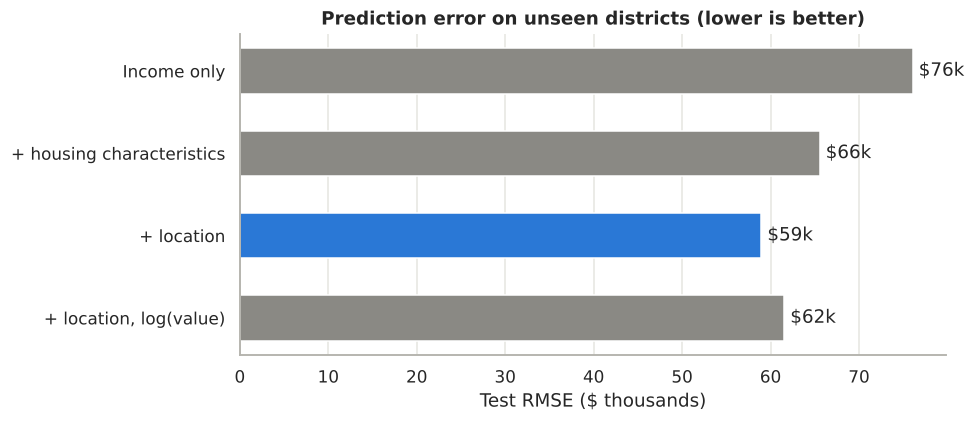

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = comparison.index.str.replace(r"^\d\. ", "", regex=True)
rmse = comparison["Test RMSE ($)"][::-1]
colors = [BLUE if v == rmse.min() else GREY for v in rmse]   # highlight the best model
bars = ax.barh(labels[::-1], rmse / 1000, color=colors, height=0.55)
ax.bar_label(bars, labels=[f"${v:,.0f}k" for v in comparison["Test RMSE ($)"][::-1] / 1000], padding=4)
ax.set(title="Prediction error on unseen districts (lower is better)", xlabel="Test RMSE ($ thousands)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "model_comparison.png", bbox_inches="tight"); plt.show()

### 9.1 Interpreting the best model

In [22]:
best_name = "3. + location"
best = fits[best_name]
coef = pd.DataFrame({"coef": best.params, "robust SE": best.bse,
                     "p-value": best.pvalues}).drop("const")
coef["95% CI low"], coef["95% CI high"] = best.conf_int().drop("const").T.values

# Standardised effect: change in value ($) for a one-standard-deviation change in each feature
coef["effect of +1 SD ($)"] = coef["coef"] * train[features].std() * 100_000
coef.sort_values("effect of +1 SD ($)", key=abs, ascending=False)

,coef,robust SE,p-value,95% CI low,95% CI high,effect of +1 SD ($)
Latitude,-0.327,0.008,0.000,-0.343,-0.311,"-70,306.731"
Longitude,-0.328,0.008,0.000,-0.344,-0.311,"-65,680.851"
MedInc,0.361,0.010,0.000,0.342,0.379,"56,459.889"
LogAveOccup,-1.026,0.026,0.000,-1.076,-0.975,"-25,165.021"
DistToCityKm,-0.002,0.000,0.000,-0.002,-0.002,"-14,741.256"
BedroomRatio,1.571,0.424,0.000,0.740,2.403,"10,729.141"
HouseAge,0.007,0.001,0.000,0.006,0.008,"8,410.315"
AveRooms,0.047,0.010,0.000,0.027,0.067,"6,019.051"
LogPopulation,0.061,0.010,0.000,0.042,0.081,"4,545.556"


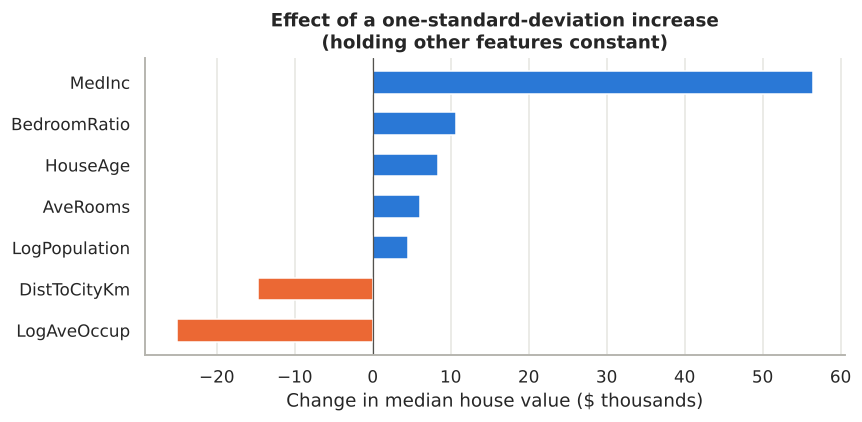

In [23]:
std_eff = coef["effect of +1 SD ($)"].drop(["Latitude", "Longitude"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(std_eff.index, std_eff / 1000, color=[ORANGE if v < 0 else BLUE for v in std_eff], height=0.55)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set(title="Effect of a one-standard-deviation increase\n(holding other features constant)",
       xlabel="Change in median house value ($ thousands)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_effects.png", bbox_inches="tight"); plt.show()

Latitude and longitude are left off this chart because of their collinearity (see §8.1).

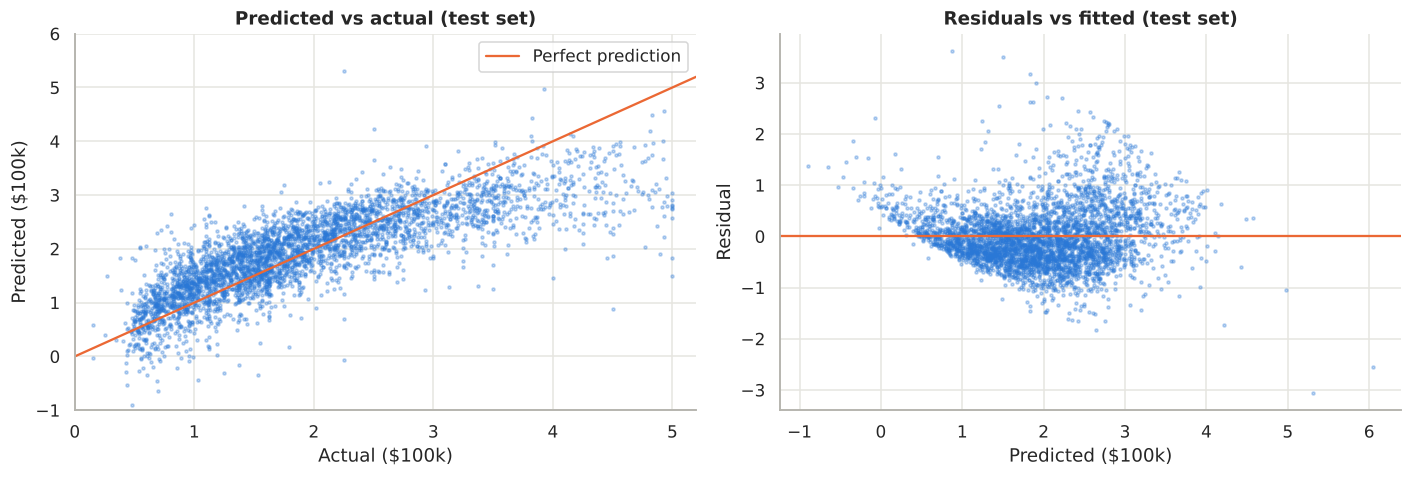

In [24]:
best_pred = best.predict(sm.add_constant(test[features]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(test["MedianHouseValue"], best_pred, s=4, alpha=0.3, color=BLUE)
lims = [0, 5.2]; axes[0].plot(lims, lims, color=ORANGE, linewidth=1.5, label="Perfect prediction")
axes[0].set(xlim=lims, ylim=[-1, 6], title="Predicted vs actual (test set)",
            xlabel="Actual ($100k)", ylabel="Predicted ($100k)"); axes[0].legend()
res_best = test["MedianHouseValue"] - best_pred
axes[1].scatter(best_pred, res_best, s=4, alpha=0.3, color=BLUE)
axes[1].axhline(0, color=ORANGE, linewidth=1.5)
axes[1].set(title="Residuals vs fitted (test set)", xlabel="Predicted ($100k)", ylabel="Residual")
plt.tight_layout(); plt.savefig(FIG_DIR / "diagnostics_best.png", bbox_inches="tight"); plt.show()

## 10. Key findings

**1. Income is the strongest single driver of house value, but explains less than half of it.**
On its own, median income explains about **47%** of the variation in district house values. Each extra \$10,000 of
median household income goes with about **\$42,000** higher median house value.

**2. The simple model has systematic problems.**
Residuals are skewed (12,265 over-predictions vs 8,375 under-predictions) and their variance grows with the fitted
value (Breusch–Pagan p < 0.001). About 5% of districts hit the \$500,001 census cap, which pulls the fitted line down.

**3. Influential districts are mostly expensive, top-coded areas.**
With the 4/n rule, 1,230 districts (6%) are influential. **59%** of them sit at the \$500k cap, compared with under
5% of the full dataset, and their median income is about 60% higher than average. Removing them changes the slope only
slightly (0.418 → 0.431), so the income effect is robust.

**4. Location and household structure add a lot.**
Adding housing characteristics and location raises test R² from **0.42 to 0.65** and cuts typical prediction error
(RMSE) from about **\$76k to \$59k** on districts the model has never seen. Holding income constant:
- districts further from San Francisco or Los Angeles are cheaper
- more crowded households (higher occupancy) go with lower values

Modelling log(value) gives the lowest *typical* error (MAE \$42k vs \$44k) but a higher RMSE. That model is the
better choice if the occasional large miss on an expensive district matters less than everyday accuracy.

**5. Train and test performance match closely,** so the models are not overfitting.

### Limitations
- **1990 data.** The relationships hold for 1990 and should not be used to price homes today.
- **Censored target.** Districts above \$500k were excluded from the multiple models. A Tobit model would handle them properly.
- **Spatial autocorrelation.** Neighbouring districts are similar (Durbin–Watson ≈ 0.66), so standard errors are probably understated even with HC3 correction.
- **Association, not causation.** Income and location move together with many unmeasured factors (schools, amenities, zoning).

### Next steps
- Spatial regression or spatially blocked cross-validation
- Tree-based models (random forest, gradient boosting) to capture non-linear location effects
- Join with current census data to test whether the 1990 patterns still hold